
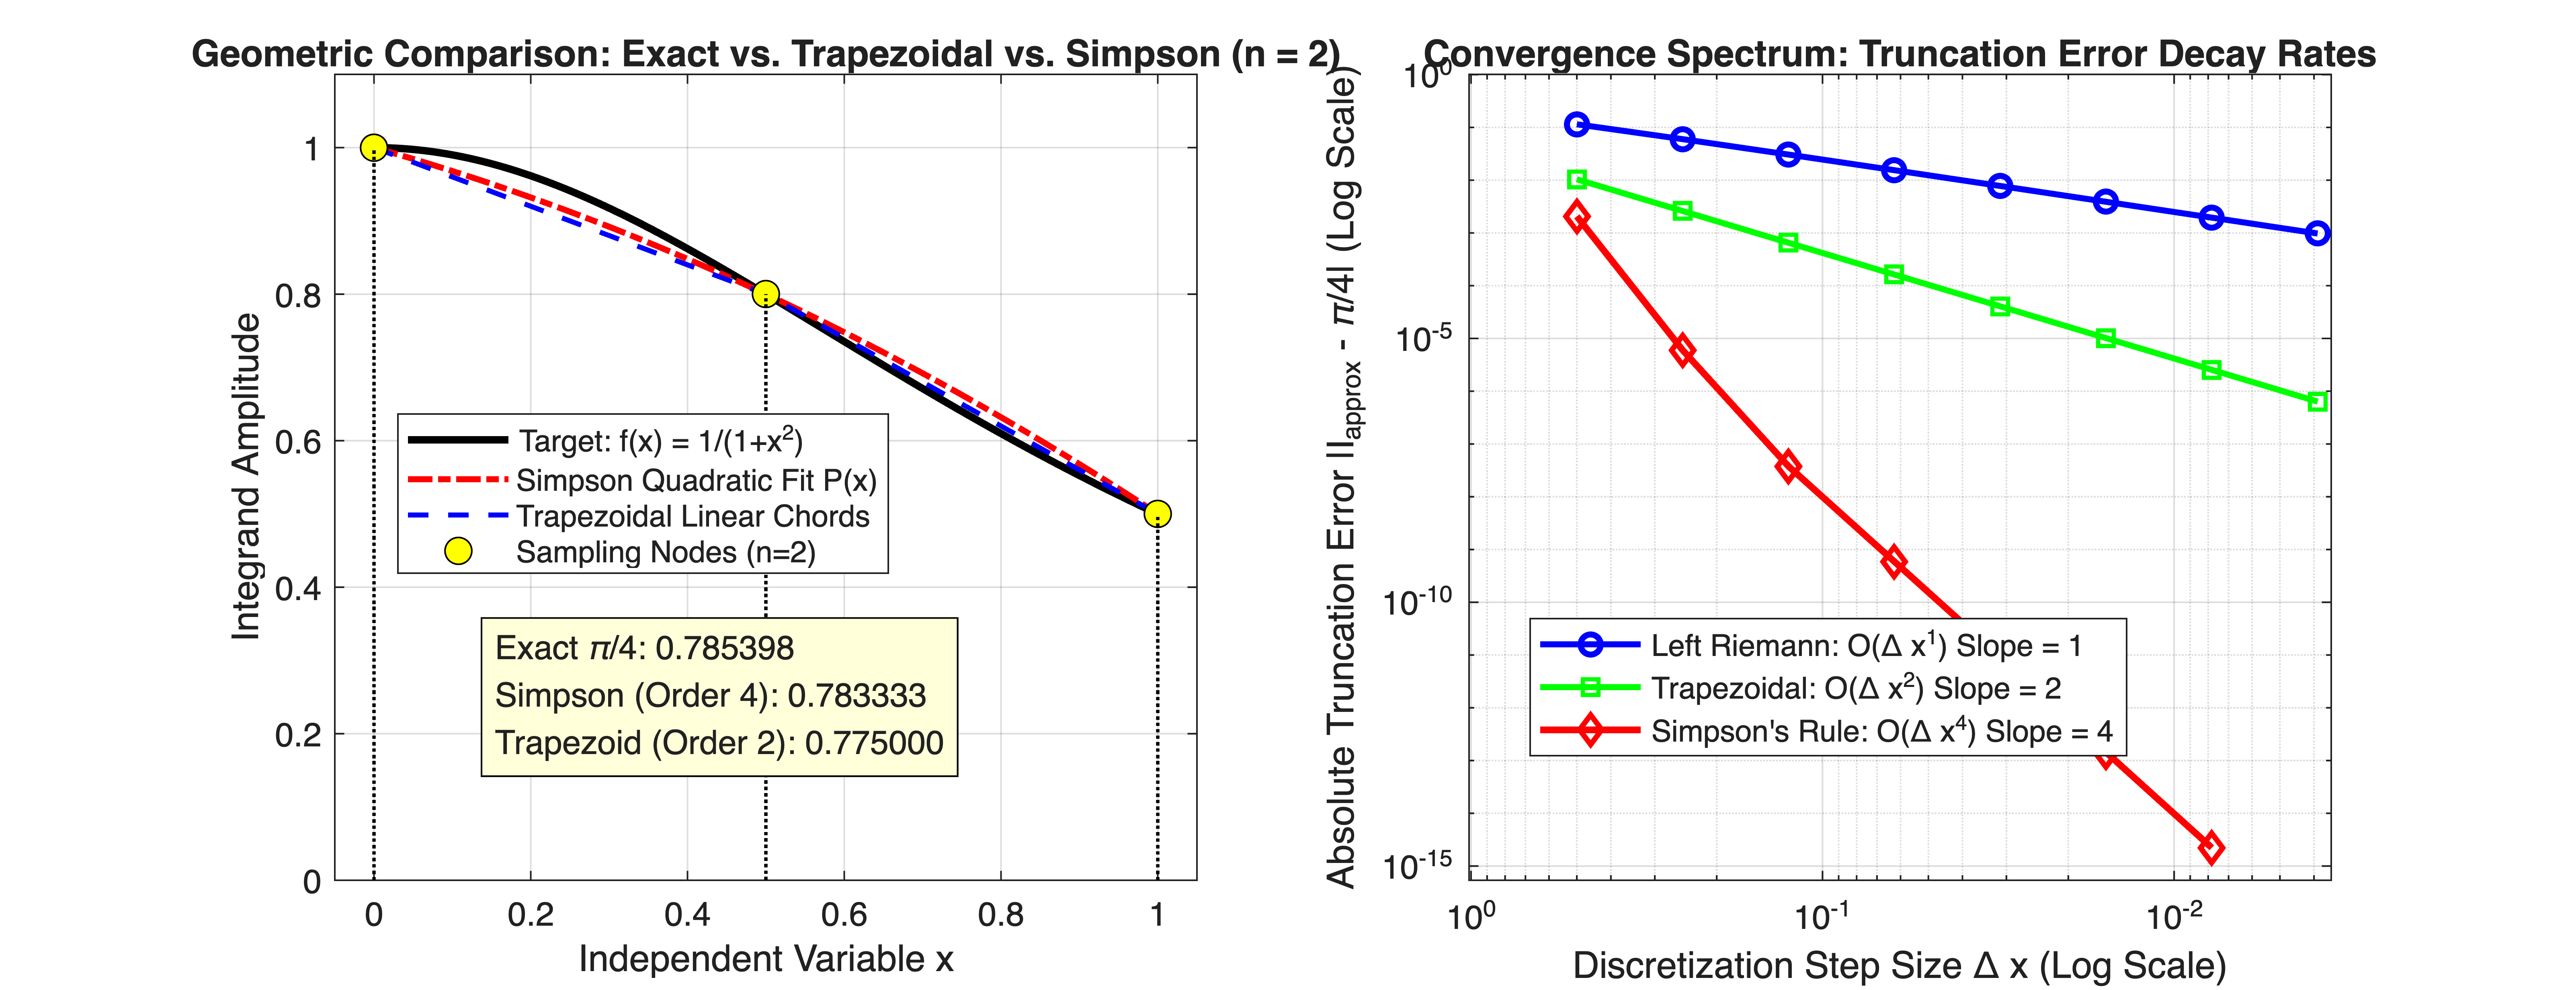

In [1]:
%% MIT 18.01 Lecture 24: Numerical Quadrature & Solver Error Orders
% Mathematical Tool Application: Used for designing fixed-step continuous-to-discrete
% ODE solvers (Forward Euler, Tustin/Trapezoidal, RK4/Simpson) and analyzing
% numerical truncation error budgets in real-time embedded control algorithms.


clear; clc; close all;


%% Part 1: Geometric Approximation of Benchmark f(x) = 1 / (1 + x^2) on [0, 1]
f = @(x) 1.0 ./ (1.0 + x.^2);
exact_integral = pi / 4.0; % Exact answer: atan(1) - atan(0) = pi / 4 approx 0.785398


% Coarse discretization with n = 2 intervals (Delta x = 0.5) from Lecture 24
a = 0.0; b = 1.0; n = 2;
dx = (b - a) / n;
x_nodes = [0.0, 0.5, 1.0];
y_nodes = f(x_nodes); % [1.0, 0.8, 0.5]


% Trapezoidal sum (n = 2): dx * (0.5*y0 + y1 + 0.5*y2) = 0.775
trap_val = dx * (0.5 * y_nodes(1) + y_nodes(2) + 0.5 * y_nodes(3));


% Simpson's sum (n = 2): (dx / 3) * (y0 + 4*y1 + y2) = 4.7 / 6 approx 0.783333
simp_val = (dx / 3.0) * (y_nodes(1) + 4 * y_nodes(2) + y_nodes(3));


% Quadratic interpolation curve for Simpson's rule over [0, 1]
% P(x) = A*x^2 + B*x + C passing through (0, 1), (0.5, 0.8), (1.0, 0.5)
poly_coeffs = polyfit(x_nodes, y_nodes, 2);
x_fine = linspace(a, b, 200);
y_exact = f(x_fine);
y_parabola = polyval(poly_coeffs, x_fine);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_fine, y_exact, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Target: f(x) = 1/(1+x^2)'); hold on;
plot(x_fine, y_parabola, 'r-.', 'LineWidth', 1.8, 'DisplayName', 'Simpson Quadratic Fit P(x)');
plot(x_nodes, y_nodes, 'b--', 'LineWidth', 1.5, 'DisplayName', 'Trapezoidal Linear Chords');
plot(x_nodes, y_nodes, 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'y', 'DisplayName', 'Sampling Nodes (n=2)');


% Draw vertical ordinate lines
for i = 1:length(x_nodes)
    plot([x_nodes(i), x_nodes(i)], [0, y_nodes(i)], 'k:', 'LineWidth', 1.0, 'HandleVisibility', 'off');
end


grid on;
xlim([-0.05, 1.05]); ylim([0, 1.1]);
xlabel('Independent Variable x');
ylabel('Integrand Amplitude');
title('Geometric Comparison: Exact vs. Trapezoidal vs. Simpson (n = 2)');
legend('Location', 'southwest');


text(0.15, 0.25, sprintf('Exact \\pi/4: %.6f\nSimpson (Order 4): %.6f\nTrapezoid (Order 2): %.6f', ...
    exact_integral, simp_val, trap_val), 'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');


%% Part 2: Order of Accuracy Convergence Spectrum (Log-Log Error Plot)
subplot(1, 2, 2);


% Subinterval counts (must be even for Simpson's rule)
n_sweep = 2 .^ (1:8); % [2, 4, 8, 16, 32, 64, 128, 256]
dx_sweep = (b - a) ./ n_sweep;


err_left_riemann = zeros(size(n_sweep));
err_trapezoidal  = zeros(size(n_sweep));
err_simpson      = zeros(size(n_sweep));


for k = 1:length(n_sweep)
    nk = n_sweep(k);
    h = dx_sweep(k);
    x_k = linspace(a, b, nk + 1);
    y_k = f(x_k);


    % 1. Left Riemann Sum: h * sum(y(1:end-1))
    val_left = h * sum(y_k(1:end-1));
    err_left_riemann(k) = abs(val_left - exact_integral);


    % 2. Trapezoidal Rule: h * (0.5*y0 + y1 + ... + 0.5*yn)
    val_trap = h * (0.5 * y_k(1) + sum(y_k(2:end-1)) + 0.5 * y_k(end));
    err_trapezoidal(k) = abs(val_trap - exact_integral);


    % 3. Simpson's 1/3 Rule: (h / 3) * (y0 + 4*y_odd + 2*y_even + yn)
    val_simp = (h / 3.0) * (y_k(1) + 4 * sum(y_k(2:2:end-1)) + 2 * sum(y_k(3:2:end-2)) + y_k(end));
    err_simpson(k) = abs(val_simp - exact_integral);
end


loglog(dx_sweep, err_left_riemann, 'b-o', 'LineWidth', 1.8, 'DisplayName', 'Left Riemann: O(\Delta x^1) Slope = 1'); hold on;
loglog(dx_sweep, err_trapezoidal,  'g-s', 'LineWidth', 1.8, 'DisplayName', 'Trapezoidal: O(\Delta x^2) Slope = 2');
loglog(dx_sweep, err_simpson,      'r-d', 'LineWidth', 2.0, 'DisplayName', 'Simpson''s Rule: O(\Delta x^4) Slope = 4');


grid on;
set(gca, 'XDir', 'reverse'); % Smaller step sizes to the right
xlabel('Discretization Step Size \Delta x (Log Scale)');
ylabel('Absolute Truncation Error |I_{approx} - \pi/4| (Log Scale)');
title('Convergence Spectrum: Truncation Error Decay Rates');
legend('Location', 'northwest');